In [ ]:
# === CABECALHO ACADEMICO (gerado por scripts/apply_header.py) ===
# Universidade Presbiteriana Mackenzie
# Disciplina: Inteligência Artificial
# Projeto: Previsão de desempenho de jogadores da NBA (pontos por jogo)
#
# INTEGRANTES DO GRUPO:
#   - Rodrigo Lucas Mascarenhas Leite Oliveira - TIA 10427925
#   - André Ihsan Ward - TIA 10425684
#
# ARQUIVO: notebooks/03_classificacao_e_calibracao.ipynb
# SINTESE: Classificação contra o patamar recente e calibração.
#
# HISTORICO DE ALTERACOES:
#   data       | autor      | descricao
#   -----------|------------|-------------------------------------------
#   2026-11-15 | Rodrigo    | Versão inicial.
# === FIM DO CABECALHO ===


# 03 - Classificação contra o patamar recente e calibração

Alvo: `y_over` = 1 se o jogador marcou **mais** que a mediana dos seus 10 jogos anteriores (`line_synthetic`). A pergunta é se o modelo produz **probabilidades calibradas**, não se acerta muito: como a linha acompanha o próprio jogador, o teto de acurácia é baixo.

**Correção em relação à N1:** a mediana de 10 inteiros pode ser inteira (ex.: 12,0), e o arredondamento para ,5 não muda isso. Nesses casos pode haver **empate** (`y_pts == linha`), rotulado como "não superou". Reportamos tudo com e sem empates.

In [2]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_columns", 30)
TV = json.loads(Path("results/metrics/treino_validacao.json").read_text(encoding="utf-8"))
TF = json.loads(Path("results/metrics/test_final.json").read_text(encoding="utf-8"))

In [3]:
from src.modeling import load_dataset, add_clf_features, clf_feature_set, CLF_EXTRA_FEATURES
df = add_clf_features(load_dataset())
emp = df["y_pts"] == df["line_synthetic"]
print(f"linha inteira em {df['linha_inteira'].mean():.1%} das linhas; empates: {emp.sum():,} ({emp.mean():.1%}), todos com y_over = {df.loc[emp, 'y_over'].unique()}")
df.groupby("linha_inteira")["y_over"].mean().rename("taxa de superação").to_frame()

linha inteira em 52.3% das linhas; empates: 2,943 (3.5%), todos com y_over = [0.]


,taxa de superação
linha_inteira,
0.000,0.503
1.000,0.465


## 1. Por que o classificador precisa ver a linha

Sozinhas, as médias recentes quase não informam se o jogador vai superar a **própria** mediana (a linha sobe e desce junto com elas). Boa parte do sinal está na **diferença** entre a média recente e a linha. Por isso o modelo recebe a linha e as diferenças: `diff_ewm_linha, diff_ma5_linha, diff_media_temporada_linha, z_ewm_linha, linha_inteira`.

In [4]:
from sklearn.metrics import roc_auc_score
tr = df[df["split"] == "train"]
pd.Series({c: roc_auc_score(tr["y_over"], tr[c]) for c in ["pts_ewm_prev", "line_synthetic", "diff_ewm_linha", "z_ewm_linha"]}, name="AUC no treino").to_frame()

,AUC no treino
pts_ewm_prev,0.477
line_synthetic,0.450
diff_ewm_linha,0.618
z_ewm_linha,0.616


## 2. Seleção (validação cruzada temporal + validação 2024-25)

In [5]:
c = TV["classificacao"]
sel = pd.DataFrame({k: {"logloss CV": -v["score_cv_medio"], "parametros": v["melhores_parametros"]} for k, v in c["cv"].items()}).T
sel["logloss validação"] = [c["validacao"][k]["log_loss"] for k in sel.index]
sel["AUC validação"] = [c["validacao"][k]["auc"] for k in sel.index]
print("modelo final:", c["modelo_final"], "| calibração escolhida:", c["calibracao"]["metodo"])
print("Brier na 2a metade da validação por método:", c["calibracao"]["brier_segunda_metade"])
sel.sort_values("logloss validação")

modelo final: logistica_l2 | calibração escolhida: sem_calibracao
Brier na 2a metade da validação por método: {'sem_calibracao': 0.23460824793158963, 'sigmoid': 0.23483030009526415, 'isotonic': 0.23520227238433566}


,logloss CV,parametros,logloss validação,AUC validação
logistica_l2,0.665,{'model__C': 3.1622776601683795},0.662,0.638
logistica_l1,0.665,{'model__C': 10.0},0.662,0.638
hgb,0.668,"{'model__min_samples_leaf': 500, 'model__max_l...",0.664,0.635
random_forest,0.669,"{'model__max_features': 0.33, 'model__min_samp...",0.664,0.633


A calibração foi escolhida **sem olhar o teste**: cada calibrador (Platt/sigmoid e isotônico) foi ajustado na primeira metade da validação e julgado na segunda. A regressão logística já sai calibrada, e nenhum calibrador melhorou o Brier, então o modelo final fica sem ajuste adicional.

## 3. Teste 2025-26

In [6]:
cols = ["acuracia", "precisao", "revocacao", "f1", "auc", "brier", "brier_ingenuo", "brier_skill", "log_loss", "ece"]
a = pd.DataFrame(TF["classificacao"]["teste"]).T[cols]
b = pd.DataFrame(TF["classificacao"]["teste_sem_empates"]).T[cols]
pd.concat({"todas as linhas": a, "sem empates": b})

acuracia  precisao  revocacao    f1   auc  \
todas as linhas constante_treino     0.520     0.000      0.000 0.000 0.500   
                logistica_l2         0.591     0.577      0.560 0.568 0.630   
                logistica_l1         0.591     0.577      0.559 0.567 0.630   
                random_forest        0.584     0.568      0.559 0.564 0.622   
                hgb                  0.588     0.574      0.547 0.560 0.624   
                final_calibrado      0.591     0.577      0.560 0.568 0.630   
sem empates     constante_treino     0.503     0.000      0.000 0.000 0.500   
                logistica_l2         0.592     0.595      0.560 0.577 0.632   
                logistica_l1         0.592     0.595      0.559 0.576 0.632   
                random_forest        0.585     0.586      0.559 0.572 0.624   
                hgb                  0.587     0.591      0.547 0.568 0.625   
                final_calibrado      0.592     0.595      0.560 0.577 0.632   

                                  brier  brier_ingenuo  brier_skill  log_loss  \
todas as linhas constante_treino  0.250          0.250        0.000     0.692   
                logistica_l2      0.237          0.250        0.052     0.666   
                logistica_l1      0.237          0.250        0.052     0.666   
                random_forest     0.238          0.250        0.046     0.669   
                hgb               0.238          0.250        0.047     0.668   
                final_calibrado   0.237          0.250        0.052     0.666   
sem empates     constante_treino  0.250          0.250        0.000     0.693   
                logistica_l2      0.237          0.250        0.054     0.666   
                logistica_l1      0.237          0.250        0.054     0.666   
                random_forest     0.238          0.250        0.049     0.668   
                hgb               0.238          0.250        0.049     0.668   
                final_calibrado   0.237          0.250        0.054     0.666   

                                   ece  
todas as linhas constante_treino 0.014  
                logistica_l2     0.012  
                logistica_l1     0.012  
                random_forest    0.012  
                hgb              0.012  
                final_calibrado  0.012  
sem empates     constante_treino 0.014  
                logistica_l2     0.013  
                logistica_l1     0.012  
                random_forest    0.011  
                hgb              0.012  
                final_calibrado  0.013

In [7]:
print("regra sem treino (média exponencial acima da linha):", TF["classificacao"]["regra_exponencial_acima_da_linha"])
print("AUC do modelo, IC por jogador:", TF["classificacao"]["auc_ic"])
print("Brier modelo - ingênuo, IC por jogador:", TF["classificacao"]["brier_vs_ingenuo"])

regra sem treino (média exponencial acima da linha): {'acuracia': 0.5686801941406935, 'auc': 0.6088417719325427, 'acuracia_sem_empates': 0.5744873888586464, 'auc_sem_empates': 0.6124041358436711}
AUC do modelo, IC por jogador: {'valor': 0.6301304725618297, 'ic_inf': 0.6222910245690773, 'ic_sup': 0.6380221936109602, 'n_boot': 1000}
Brier modelo - ingênuo, IC por jogador: {'delta': -0.012992632366254085, 'ic_inf': -0.014490012673073474, 'ic_sup': -0.011501393490603104, 'p_valor': 0.0, 'n_clusters': 450, 'n_boot': 2000}


### Ablação das features da classificação

In [8]:
pd.DataFrame(TF["classificacao"]["ablacao"]).T[["acuracia", "auc", "brier", "brier_skill", "log_loss"]]

,acuracia,auc,brier,brier_skill,log_loss
completo,0.591,0.630,0.237,0.052,0.666
sem_linha_inteira,0.589,0.628,0.237,0.051,0.667
so_pre_jogo,0.571,0.602,0.242,0.032,0.676


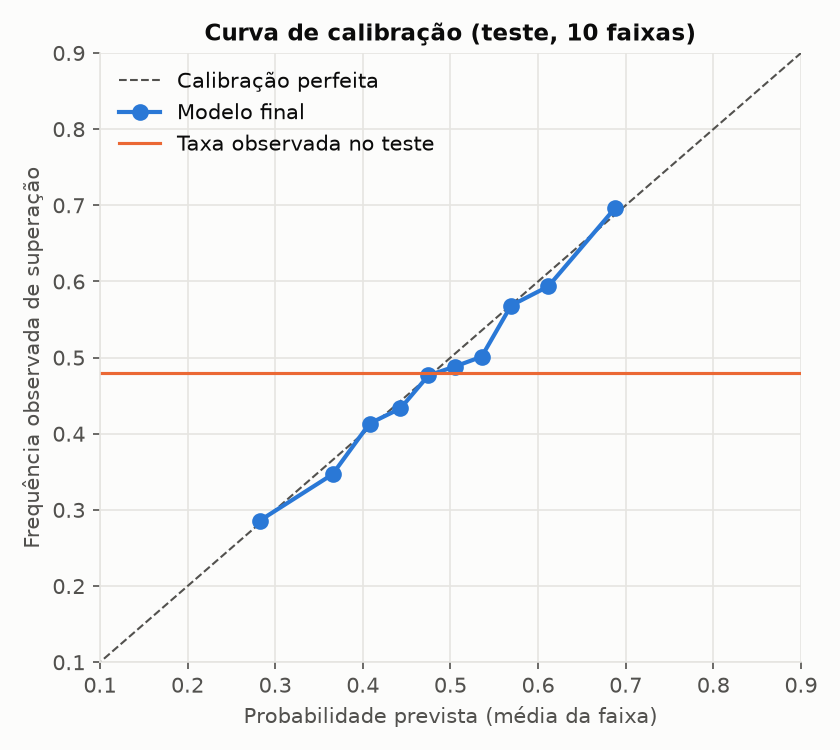

,faixa,n,prob_media_prevista,frequencia_observada
0,1,1711,0.282,0.286
1,2,1710,0.365,0.347
2,3,1710,0.408,0.413
3,4,1710,0.443,0.433
4,5,1710,0.475,0.477
5,6,1710,0.505,0.488
6,7,1710,0.536,0.501
7,8,1710,0.569,0.568
8,9,1710,0.612,0.594
9,10,1710,0.688,0.696


In [9]:
display(Image("results/figures/f_curva_calibracao.png", width=520))
pd.DataFrame(TF["classificacao"]["curva_calibracao"])

## Leitura

- O classificador supera o estimador ingênuo (probabilidade constante): Brier menor com IC longe de zero e AUC ≈ 0,63, acima da regra simples "média exponencial acima da linha" (≈ 0,61).
- As probabilidades são calibradas: a curva acompanha a diagonal (quando o modelo diz 60%, o jogador supera a linha perto de 60% das vezes). O ECE baixo é necessário mas não suficiente, porque o estimador constante também o tem; a vantagem está na resolução (Brier e AUC).
- Os empates (3,3% do teste) não explicam o resultado: sem eles as métricas praticamente não mudam, e remover `linha_inteira` custa pouco.
- Sem as features relativas à linha (`so_pre_jogo`) a AUC cai de 0,630 para 0,602: elas acrescentam sinal, mas boa parte já vem das variáveis de volume, minutos e histórico. O sinal mistura tendência recente, assimetria e reversão ao patamar da temporada.
- O ganho é modesto, como previsto: a linha é a mediana do próprio jogador e a maior parte da variação de um jogo para outro não é previsível com informação pré-jogo.